# Cohen et al. 2021 — Multiple Myeloma · 04 EMT-TF Expression
Unconditional final notebook. Score EMT transcription factors **gated on detectable expression**
across a panel that includes Snail/Zeb/Twist **and** the FOXC / PRRX mesenchymal families (VIM is a
marker, not a TF, so it is excluded). Overlay thresholded expressers as a categorical layer on the
grey manifold (reference plotting style).

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']       # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(float(t.min()),2), '->', round(float(t.max()),2))

cells: 33019 | pseudotime range 0.0 -> 3.18


In [ ]:
# EMT-TF panel gated on detectable expression (frac cells with counts > 0).
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]
    rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
print('\ndetectably-expressed EMT-TFs (frac_expr > 0.03):', ok.TF.tolist())
print('MM plasma cells are terminally differentiated: only ZEB1 clears the detection floor;')
print('all Snail/Twist/FOXC/PRRX/ZEB2 factors are near-silent (<0.3%) -> ZEB1 is the sole informative TF.')

    TF  frac_expr  mean_early  mean_late  rho_vs_t
  ZEB2      0.002       0.002      0.001    -0.009
 FOXC2      0.000       0.000      0.000    -0.009
 SNAI1      0.001       0.001      0.000    -0.008
 SNAI2      0.002       0.001      0.000    -0.006
TWIST1      0.001       0.001      0.001    -0.005
 PRRX1      0.002       0.002      0.001    -0.004
 FOXC1      0.000       0.000      0.000    -0.003
TWIST2      0.000       0.000      0.000     0.001
 PRRX2      0.000       0.000      0.000     0.003
  ZEB1      0.032       0.018      0.022     0.033

detectably-expressed EMT-TFs (frac_expr > 0.03): ['ZEB1']
MM plasma cells are terminally differentiated: only ZEB1 clears the detection floor;
all Snail/Twist/FOXC/PRRX/ZEB2 factors are near-silent (<0.3%) -> ZEB1 is the sole informative TF.


ZEB1: 3.2% expressing; 267 shown (upper quartile), mean pseudotime shown = 0.44 (all = 0.47)
saved expression.pdf


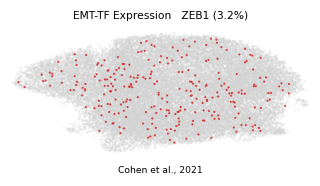

In [ ]:
# EMT-TF overlay — categorical thresholded expressers on the grey manifold (reference style).
def vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
show = ok.TF.tolist() if len(ok) else [df.sort_values('frac_expr').iloc[-1]['TF']]
palette = ['tab:red','tab:blue','tab:green','tab:purple']
thr = {}; sel = {}
for g in show:
    v = vec(g); pos = v[v>0]
    thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
    sel[g] = v > thr[g]
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=8, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
order = sorted(show, key=lambda g: -int(sel[g].sum()))
cmap = {g:palette[i] for i,g in enumerate(show)}
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=cmap[g], size=8, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
lbl = ' · '.join('%s (%.1f%%)' % (g, (vec(g)>0).mean()*100) for g in show)
ax.set_title('EMT-TF Expression   ' + lbl, size=7)
ax.text(.5,-.14,'Cohen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in show:
    print('%s: %.1f%% expressing; %d shown (upper quartile), mean pseudotime shown = %.2f (all = %.2f)'
          % (g, (vec(g)>0).mean()*100, int(sel[g].sum()), tn[sel[g]].mean(), tn.mean()))
print('saved expression.pdf')